train: 1312  val: 281  test: 282
Training Swin-UNet + MaxSig + MSALoss
epoch  1  started!  LR= [0.0001]
train_loss:  1.2213934409182245
val_loss:  0.9292832612991333
Validation_Dice Score = 0.567914297183
The best model saved...
Best validation dice= 0.5679142971833547  in epoch  1
Epoch finished in 16.443441299023107 seconds.

epoch  2  started!  LR= [0.0001]
train_loss:  0.8281428443222512
val_loss:  0.7654946164952384
Validation_Dice Score = 0.654218826029
The best model saved...
Best validation dice= 0.6542188260290358  in epoch  2
Epoch finished in 17.452907783910632 seconds.

epoch  3  started!  LR= [0.0001]
train_loss:  0.7452315239281189
val_loss:  0.7493205136722989
Validation_Dice Score = 0.655021514330
The best model saved...
Best validation dice= 0.6550215143296454  in epoch  3
Epoch finished in 17.412887101992965 seconds.

epoch  4  started!  LR= [0.0001]
train_loss:  0.6920470722564837
val_loss:  0.6809133340915045
Validation_Dice Score = 0.708933974306
The best model sav

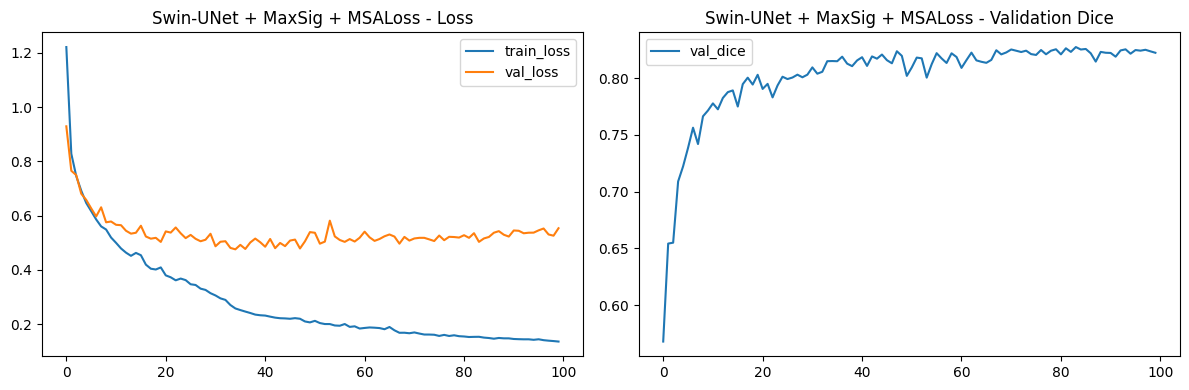

In [2]:
"""
Swin-UNet + MaxSig + MSALoss on BUSBRA — training + test evaluation
"""

import os
import math
from glob import glob
from time import perf_counter

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR

# ============================================================
# 0) Config
# ============================================================
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSBRA/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "img_size": 224,
}

# ============================================================
# 1) Dataset
# ============================================================
class mydataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms_img=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.transforms_img = transforms_img
        self.mask_names = glob(masks_dir + "*.png")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self, index):
        mask_name = self.mask_names[index]
        mask = cv2.imread(mask_name, cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())
        mask = (mask > 0).astype(np.float32)
        mask = cv2.resize(mask, (224, 224), interpolation=cv2.INTER_AREA)

        imgn = mask_name.replace('/masks/', '/images/').replace('/mask_', '/bus_')
        image = cv2.imread(imgn, cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)
        image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

def build_dataloaders(root, batch_size, img_size=224):
    resize = A.Resize(img_size, img_size)
    train_transform = A.Compose([resize, ToTensorV2()])
    val_transform = A.Compose([resize, ToTensorV2()])
    test_transform = A.Compose([resize, ToTensorV2()])

    train_ds = mydataset(root + 'dataset/train/images/', root + 'dataset/train/masks/', train_transform)
    val_ds = mydataset(root + 'dataset/val/images/', root + 'dataset/val/masks/', val_transform)
    test_ds = mydataset(root + 'dataset/test/images/', root + 'dataset/test/masks/', test_transform)

    print("train:", len(train_ds), " val:", len(val_ds), " test:", len(test_ds))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader

# ============================================================
# 2) MaxSigLayerNormalized & MSALoss
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    def __init__(self, ch_in, ch_out, kernel_size, stride=1, use_sigmoid_input=True):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in, self.ch_out = ch_in, ch_out
        self.kernel_size, self.stride = kernel_size, stride
        self.use_sigmoid_input = use_sigmoid_input
        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x):
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"
        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(x_in, kernel_size=self.kernel_size, padding=self.padding, stride=self.stride)
        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1
        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)
        b = torch.sigmoid(self.bias)
        D = torch.maximum(w, x_unfold) + b

        mean_stat = D.mean(dim=2)
        median_stat, _ = D.median(dim=2)
        center_values = x_unfold[:, :, self.center_index, :, :]

        out = (self.weight_center * center_values + self.weight_median * median_stat - mean_stat)
        return self.proj(out)

class GatedMaxSigWrapperSwin(nn.Module):
    def __init__(self, inner_module, ch, kernel_sig=3, gamma_init=0.0, use_sigmoid_input=True):
        super().__init__()
        self.inner = inner_module
        self.maxsig = MaxSigLayerNormalized(ch, ch, kernel_sig, use_sigmoid_input=use_sigmoid_input)
        self.post = nn.Sequential(nn.BatchNorm2d(ch), nn.LeakyReLU(0.1, inplace=True))
        self.gamma = nn.Parameter(torch.tensor(gamma_init))

    def forward(self, x, Wh, Ww):
        x_out, H, W, x, Wh, Ww = self.inner(x, Wh, Ww)
        # FIXED: x_out from BasicLayer.forward is flattened [B, H*W, C]
        # (both the downsample and no-downsample branches return the
        # post-block tensor in that shape), NOT [B, H, W, C]. Reshape to
        # spatial before the permute, then flatten back so downstream code
        # (x_downsample skip list, and the `x + x_downsample[...]` addition
        # in SwinTransformerSys.forward, which operates on flattened
        # [B, L, C] tensors) keeps working unchanged. This was the exact
        # cause of: "permute(sparse_coo): ... input.dim() = 3 is not equal
        # to len(dims) = 4".
        B, L, C = x_out.shape
        x_spatial = x_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()  # [B, C, H, W]
        m = self.post(self.maxsig(x_spatial))
        out_spatial = x_spatial + self.gamma * m
        x_out = out_spatial.permute(0, 2, 3, 1).contiguous().view(B, H * W, C)
        return x_out, H, W, x, Wh, Ww

class MaxSigFeatureHook:
    def __init__(self, model):
        self.features = {}
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, MaxSigLayerNormalized):
                self.handles.append(module.register_forward_hook(self._make_hook(name)))
    def _make_hook(self, name):
        def hook(_, __, output):
            self.features[name] = output
        return hook
    def clear(self):
        self.features.clear()
    def remove(self):
        for h in self.handles:
            h.remove()

def _local_stats(x, k=3):
    B, C, H, W = x.shape
    pad = k // 2
    uf = F.unfold(x, kernel_size=k, padding=pad)
    uf = uf.view(B, C, k * k, H, W)
    center = uf[:, :, k * k // 2, :, :]
    mean_l = uf.mean(dim=2)
    med_l, _ = uf.median(dim=2)
    return center, mean_l, med_l

class MaxSigAwareLoss(nn.Module):
    def __init__(self, alpha_bce=1.0, alpha_dice=1.0, alpha_sas=0.5,
                 alpha_mbe=0.3, alpha_mmd=0.2, alpha_pdr=1e-3, k=3, eps=1e-7):
        super().__init__()
        self.a_bce = alpha_bce; self.a_dice = alpha_dice; self.a_sas = alpha_sas
        self.a_mbe = alpha_mbe; self.a_mmd = alpha_mmd; self.a_pdr = alpha_pdr
        self.k = k; self.eps = eps
        self.bce = nn.BCEWithLogitsLoss(reduction='none')

    def sas_loss(self, probs, targets):
        pc, pm, pmd = _local_stats(probs, self.k)
        tc, tm, tmd = _local_stats(targets, self.k)
        sig_p = (pc - pm).abs() + (pc - pmd).abs()
        sig_t = (tc - tm).abs() + (tc - tmd).abs()
        sig_p = sig_p / (sig_p.amax(dim=(2, 3), keepdim=True) + self.eps)
        sig_t = sig_t / (sig_t.amax(dim=(2, 3), keepdim=True) + self.eps)
        return F.l1_loss(sig_p, sig_t)

    def mbe_loss(self, logits, targets):
        bce = self.bce(logits, targets)
        pc, pm, _ = _local_stats(torch.sigmoid(logits), self.k)
        tc, tm, _ = _local_stats(targets, self.k)
        bnd_p = (pc - pm).abs(); bnd_t = (tc - tm).abs()
        w = torch.maximum(bnd_p, bnd_t)
        w = w / (w.mean() + self.eps)
        return (bce * w).mean()

    def mmd_loss(self, probs, targets):
        _, pm, pmd = _local_stats(probs, self.k)
        _, tm, tmd = _local_stats(targets, self.k)
        div_p = (pm - pmd).abs(); div_t = (tm - tmd).abs()
        return F.l1_loss(div_p, div_t)

    def pdr_loss(self, model):
        reg = None
        for m in model.modules():
            if isinstance(m, MaxSigLayerNormalized):
                w = torch.sigmoid(m.weight).clamp(self.eps, 1 - self.eps)
                p = w / (w.sum() + self.eps)
                ent = -(p * p.log()).sum()
                pos_pen = F.relu(-m.weight_center) + F.relu(-m.weight_median)
                bal = (m.weight_center - m.weight_median).abs()
                term = -ent + pos_pen + 0.1 * bal
                reg = term if reg is None else reg + term
        return reg if reg is not None else torch.tensor(0.0, device=next(model.parameters()).device)

    def dice_loss(self, probs, targets):
        inter = (probs * targets).sum(dim=(2, 3))
        union = (probs + targets).sum(dim=(2, 3))
        dice = (2 * inter + self.eps) / (union + self.eps)
        return 1 - dice.mean()

    def forward(self, logits, targets, model=None):
        probs = torch.sigmoid(logits)
        loss  = self.a_bce  * self.bce(logits, targets).mean()
        loss  = loss + self.a_dice * self.dice_loss(probs, targets)
        loss  = loss + self.a_sas  * self.sas_loss(probs, targets)
        loss  = loss + self.a_mbe  * self.mbe_loss(logits, targets)
        loss  = loss + self.a_mmd  * self.mmd_loss(probs, targets)
        if model is not None and self.a_pdr > 0:
            loss = loss + self.a_pdr * self.pdr_loss(model)
        return loss

# ============================================================
# 3) Swin-UNet Architecture
# ============================================================
def trunc_normal_(tensor, mean=0., std=1., a=-2., b=2.):
    def norm_cdf(x):
        return (1. + math.erf(x / math.sqrt(2.))) / 2.
    with torch.no_grad():
        l = norm_cdf((a - mean) / std)
        u = norm_cdf((b - mean) / std)
        tensor.uniform_(2 * l - 1, 2 * u - 1)
        tensor.erfinv_()
        tensor.mul_(std * math.sqrt(2.))
        tensor.add_(mean)
        tensor.clamp_(min=a, max=b)
        return tensor

class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)
    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.):
        super().__init__()
        self.drop_prob = drop_prob
    def forward(self, x):
        if self.drop_prob == 0. or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor

def window_partition(x, window_size):
    B, H, W, C = x.shape
    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
    windows = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)
    return windows

def window_reverse(windows, window_size, H, W):
    B = int(windows.shape[0] / (H * W / window_size / window_size))
    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)
    x = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)
    return x

class WindowAttention(nn.Module):
    def __init__(self, dim, window_size, num_heads, qkv_bias=True, qk_scale=None, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim ** -0.5
        self.relative_position_bias_table = nn.Parameter(torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))
        coords_h = torch.arange(self.window_size[0])
        coords_w = torch.arange(self.window_size[1])
        coords = torch.stack(torch.meshgrid([coords_h, coords_w]))
        coords_flatten = torch.flatten(coords, 1)
        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative_coords = relative_coords.permute(1, 2, 0).contiguous()
        relative_coords[:, :, 0] += self.window_size[0] - 1
        relative_coords[:, :, 1] += self.window_size[1] - 1
        relative_coords[:, :, 0] *= 2 * self.window_size[1] - 1
        relative_position_index = relative_coords.sum(-1)
        self.register_buffer("relative_position_index", relative_position_index)
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=.02)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        q = q * self.scale
        attn = (q @ k.transpose(-2, -1))
        relative_position_bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(
            self.window_size[0] * self.window_size[1], self.window_size[0] * self.window_size[1], -1)
        relative_position_bias = relative_position_bias.permute(2, 0, 1).contiguous()
        attn = attn + relative_position_bias.unsqueeze(0)
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.num_heads, N, N)
            attn = self.softmax(attn)
        else:
            attn = self.softmax(attn)
        attn = self.attn_drop(attn)
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        x = self.proj_drop(self.proj(x))
        return x

class SwinTransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, window_size=7, shift_size=0, mlp_ratio=4., qkv_bias=True, qk_scale=None,
                 drop=0., attn_drop=0., drop_path=0., act_layer=nn.GELU, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.window_size = window_size
        self.shift_size = shift_size
        self.mlp_ratio = mlp_ratio
        self.norm1 = norm_layer(dim)
        self.attn = WindowAttention(dim, window_size=(window_size, window_size), num_heads=num_heads,
                                    qkv_bias=qkv_bias, qk_scale=qk_scale, attn_drop=attn_drop, proj_drop=drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        self.norm2 = norm_layer(dim)
        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = Mlp(in_features=dim, hidden_features=mlp_hidden_dim, act_layer=act_layer, drop=drop)
        self.H = None
        self.W = None

    def forward(self, x, mask_matrix):
        B, L, C = x.shape
        H, W = self.H, self.W
        shortcut = x
        x = self.norm1(x)
        x = x.view(B, H, W, C)
        pad_l = pad_t = 0
        pad_r = (self.window_size - W % self.window_size) % self.window_size
        pad_b = (self.window_size - H % self.window_size) % self.window_size
        x = F.pad(x, (0, 0, pad_l, pad_r, pad_t, pad_b))
        _, Hp, Wp, _ = x.shape
        if self.shift_size > 0:
            shifted_x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
            attn_mask = mask_matrix
        else:
            shifted_x = x
            attn_mask = None
        x_windows = window_partition(shifted_x, self.window_size)
        x_windows = x_windows.view(-1, self.window_size * self.window_size, C)
        attn_windows = self.attn(x_windows, mask=attn_mask)
        attn_windows = attn_windows.view(-1, self.window_size, self.window_size, C)
        shifted_x = window_reverse(attn_windows, self.window_size, Hp, Wp)
        if self.shift_size > 0:
            x = torch.roll(shifted_x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        else:
            x = shifted_x
        if pad_r > 0 or pad_b > 0:
            x = x[:, :H, :W, :].contiguous()
        x = x.view(B, H * W, C)
        x = shortcut + self.drop_path(x)
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x

class PatchMerging(nn.Module):
    def __init__(self, dim, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = norm_layer(4 * dim)
    def forward(self, x, H, W):
        B, L, C = x.shape
        x = x.view(B, H, W, C)
        pad_input = (H % 2 == 1) or (W % 2 == 1)
        if pad_input:
            x = F.pad(x, (0, 0, 0, W % 2, 0, H % 2))
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        x = torch.cat([x0, x1, x2, x3], -1)
        x = x.view(B, -1, 4 * C)
        x = self.norm(x)
        x = self.reduction(x)
        return x

# ------------------------------------------------------------
# PatchExpand: correct 2x spatial / channel-halving rearrange:
# (H, W, 2*dim) -> (2H, 2W, dim/2)
# i.e. b h w (p1 p2 c) -> b (h p1) (w p2) c   with p1=p2=2
# ------------------------------------------------------------
class PatchExpand(nn.Module):
    def __init__(self, dim, dim_scale=2, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.expand = nn.Linear(dim, 2 * dim, bias=False) if dim_scale == 2 else nn.Identity()
        self.norm = norm_layer(dim // dim_scale)

    def forward(self, x, H, W):
        x = self.expand(x)
        B, L, C = x.shape
        assert L == H * W, "PatchExpand: input feature has wrong size"
        x = x.view(B, H, W, C)
        x = x.view(B, H, W, 2, 2, C // 4)             # split channels into (p1, p2, c)
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()  # -> B, H, p1, W, p2, c
        x = x.view(B, H * 2, W * 2, C // 4)           # merge p1/p2 into spatial dims
        x = x.view(B, -1, C // 4)
        x = self.norm(x)
        return x

# ------------------------------------------------------------
# Dedicated class for the final 4x spatial expansion back to
# the original patch resolution (patch_size=4).
# ------------------------------------------------------------
class FinalPatchExpand_X4(nn.Module):
    def __init__(self, dim, dim_scale=4, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.dim_scale = dim_scale
        self.expand = nn.Linear(dim, (dim_scale ** 2) * dim, bias=False)
        self.norm = norm_layer(dim)

    def forward(self, x, H, W):
        x = self.expand(x)
        B, L, C = x.shape
        assert L == H * W, "FinalPatchExpand_X4: input feature has wrong size"
        p = self.dim_scale
        x = x.view(B, H, W, C)
        x = x.view(B, H, W, p, p, C // (p * p))
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(B, H * p, W * p, C // (p * p))
        x = x.view(B, -1, self.dim)
        x = self.norm(x)
        return x

class BasicLayer(nn.Module):
    def __init__(self, dim, depth, num_heads, window_size=7, mlp_ratio=4., qkv_bias=True, qk_scale=None,
                 drop=0., attn_drop=0., drop_path=0., norm_layer=nn.LayerNorm, downsample=None):
        super().__init__()
        self.window_size = window_size
        self.shift_size = window_size // 2
        self.depth = depth
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim=dim, num_heads=num_heads, window_size=window_size,
                                 shift_size=0 if (i % 2 == 0) else window_size // 2,
                                 mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                                 drop=drop, attn_drop=attn_drop,
                                 drop_path=drop_path[i] if isinstance(drop_path, list) else drop_path,
                                 norm_layer=norm_layer) for i in range(depth)])
        self.downsample = downsample(dim=dim, norm_layer=norm_layer) if downsample else None

    def forward(self, x, H, W):
        Hp = int(math.ceil(H / self.window_size)) * self.window_size
        Wp = int(math.ceil(W / self.window_size)) * self.window_size
        img_mask = torch.zeros((1, Hp, Wp, 1), device=x.device)
        cnt = 0
        for h in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None)):
            for w in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None)):
                img_mask[:, h, w, :] = cnt
                cnt += 1
        mask_windows = window_partition(img_mask, self.window_size)
        mask_windows = mask_windows.view(-1, self.window_size * self.window_size)
        attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
        attn_mask = attn_mask.masked_fill(attn_mask != 0, float(-100.0)).masked_fill(attn_mask == 0, float(0.0))
        for blk in self.blocks:
            blk.H, blk.W = H, W
            x = blk(x, attn_mask)
        if self.downsample is not None:
            x_down = self.downsample(x, H, W)
            Wh, Ww = (H + 1) // 2, (W + 1) // 2
            return x, H, W, x_down, Wh, Ww
        else:
            return x, H, W, x, H, W

class BasicLayer_up(nn.Module):
    def __init__(self, dim, depth, num_heads, window_size=7, mlp_ratio=4., qkv_bias=True, qk_scale=None,
                 drop=0., attn_drop=0., drop_path=0., norm_layer=nn.LayerNorm, upsample=None):
        super().__init__()
        self.window_size = window_size
        self.shift_size = window_size // 2
        self.depth = depth
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim=dim, num_heads=num_heads, window_size=window_size,
                                 shift_size=0 if (i % 2 == 0) else window_size // 2,
                                 mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                                 drop=drop, attn_drop=attn_drop,
                                 drop_path=drop_path[i] if isinstance(drop_path, list) else drop_path,
                                 norm_layer=norm_layer) for i in range(depth)])
        self.upsample = upsample(dim=dim, norm_layer=norm_layer) if upsample else None

    def forward(self, x, H, W):
        Hp = int(math.ceil(H / self.window_size)) * self.window_size
        Wp = int(math.ceil(W / self.window_size)) * self.window_size
        img_mask = torch.zeros((1, Hp, Wp, 1), device=x.device)
        cnt = 0
        for h in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None)):
            for w in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None)):
                img_mask[:, h, w, :] = cnt
                cnt += 1
        mask_windows = window_partition(img_mask, self.window_size)
        mask_windows = mask_windows.view(-1, self.window_size * self.window_size)
        attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
        attn_mask = attn_mask.masked_fill(attn_mask != 0, float(-100.0)).masked_fill(attn_mask == 0, float(0.0))
        for blk in self.blocks:
            blk.H, blk.W = H, W
            x = blk(x, attn_mask)
        if self.upsample is not None:
            x_up = self.upsample(x, H, W)
            Wh, Ww = H * 2, W * 2
            return x, H, W, x_up, Wh, Ww
        else:
            return x, H, W, x, H, W

class SwinTransformerSys(nn.Module):
    def __init__(self, img_size=224, patch_size=4, in_chans=3, num_classes=1,
                 embed_dim=96, depths=[2, 2, 2, 2], num_heads=[3, 6, 12, 24],
                 window_size=7, mlp_ratio=4., qkv_bias=True, qk_scale=None,
                 drop_rate=0., attn_drop_rate=0., drop_path_rate=0.1,
                 norm_layer=nn.LayerNorm, patch_norm=True, use_maxsig=False, maxsig_kernel=3):
        super().__init__()
        self.num_classes = num_classes
        self.num_layers = len(depths)
        self.embed_dim = embed_dim
        self.patch_norm = patch_norm
        self.num_features = embed_dim
        self.mlp_ratio = mlp_ratio
        self.patch_embed = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.pos_drop = nn.Dropout(p=drop_rate)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]

        self.layers = nn.ModuleList()
        for i_layer in range(self.num_layers):
            layer = BasicLayer(dim=int(embed_dim * 2 ** i_layer),
                               depth=depths[i_layer], num_heads=num_heads[i_layer], window_size=window_size,
                               mlp_ratio=self.mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                               drop=drop_rate, attn_drop=attn_drop_rate,
                               drop_path=dpr[sum(depths[:i_layer]):sum(depths[:i_layer + 1])],
                               norm_layer=norm_layer,
                               downsample=PatchMerging if (i_layer < self.num_layers - 1) else None)
            # Only wrap stages that actually produce a skip connection
            # (i_layer < num_layers - 1). The bottleneck stage's x_out is
            # never used (SwinTransformerSys.forward only stores
            # x_downsample for i < num_layers - 1), so wrapping it with
            # MaxSig would create dead parameters that run every forward
            # pass but never get gradient.
            if use_maxsig and i_layer < self.num_layers - 1:
                ch = int(embed_dim * 2 ** i_layer)
                layer = GatedMaxSigWrapperSwin(layer, ch=ch, kernel_sig=maxsig_kernel, gamma_init=0.0)
            self.layers.append(layer)

        # upsample must run on stages 0..num_layers-2 (all but the last /
        # highest-resolution decoder stage), matching the encoder's
        # downsample=... convention.
        self.layers_up = nn.ModuleList()
        for i_layer in range(self.num_layers):
            layer = BasicLayer_up(dim=int(embed_dim * 2 ** (self.num_layers - 1 - i_layer)),
                                  depth=depths[self.num_layers - 1 - i_layer], num_heads=num_heads[self.num_layers - 1 - i_layer],
                                  window_size=window_size, mlp_ratio=self.mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                                  drop=drop_rate, attn_drop=attn_drop_rate,
                                  drop_path=dpr[sum(depths[:self.num_layers - 1 - i_layer]):sum(depths[:self.num_layers - i_layer])],
                                  norm_layer=norm_layer, upsample=PatchExpand if (i_layer < self.num_layers - 1) else None)
            self.layers_up.append(layer)

        self.norm_up = norm_layer(embed_dim)

        # Dedicated 4x expansion (not a reused 2x PatchExpand).
        self.final_patch_expand = FinalPatchExpand_X4(embed_dim, 4, norm_layer)
        self.final_norm = norm_layer(embed_dim)

        # final_patch_expand already restores full spatial resolution
        # (img_size), so this only needs to map channels -> num_classes
        # via a 1x1 conv, not another spatial upsample.
        self.up = nn.Conv2d(embed_dim, num_classes, kernel_size=1)

    def forward(self, x):
        x = self.patch_embed(x)
        Wh, Ww = x.size(2), x.size(3)
        x = x.flatten(2).transpose(1, 2)
        x = self.pos_drop(x)
        x_downsample = []
        for i in range(self.num_layers):
            layer = self.layers[i]
            x_out, H, W, x, Wh, Ww = layer(x, Wh, Ww)
            if i < self.num_layers - 1:
                x_downsample.append(x_out)
        for i in range(self.num_layers):
            layer = self.layers_up[i]
            x_out, H, W, x, Wh, Ww = layer(x, Wh, Ww)
            if i < self.num_layers - 1:
                x = x + x_downsample[self.num_layers - 2 - i]
        x = self.norm_up(x)
        x = self.final_patch_expand(x, Wh, Ww)
        x = self.final_norm(x)
        B, L, C = x.shape
        x = x.view(B, Wh * 4, Ww * 4, C).permute(0, 3, 1, 2).contiguous()
        x = self.up(x)
        return x

# ============================================================
# 4) Metrics
# ============================================================
@torch.no_grad()
def dice_score(logits, targets, eps=1e-7):
    preds = (torch.sigmoid(logits) > 0.5).float()
    inter = (preds * targets).sum()
    union = (preds + targets).sum()
    return float((2 * inter + eps) / (union + eps))

def prep_batch(inputs, mask, device):
    x = inputs.to(device).float()
    if x.dim() == 3:
        x = x.unsqueeze(1)
    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    y = mask.to(device).unsqueeze(1).float()
    return x, y

# ============================================================
# 5) Train / eval loop
# ============================================================
def train_one(model, train_loader, val_loader, device, epochs, lr,
              loss_fn, tag="model", ckpt_path=None):
    model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    scheduler = StepLR(optimizer, step_size=max(1, epochs // 3), gamma=0.5)
    scaler = torch.amp.GradScaler('cuda') if device == "cuda" else None

    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_dice = 0.0
    best_epoch = 0

    for epoch in range(epochs):
        t0 = perf_counter()
        current_lr = optimizer.param_groups[0]['lr']
        print(f"epoch  {epoch + 1}  started!  LR= [{current_lr}]")

        model.train()
        running = 0.0
        for inputs, mask in train_loader:
            x, y = prep_batch(inputs, mask, device)
            optimizer.zero_grad()
            if scaler is not None:
                with torch.autocast(device_type="cuda"):
                    logits = model(x)
                    loss = loss_fn(logits, y, model=model)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                logits = model(x)
                loss = loss_fn(logits, y, model=model)
                loss.backward()
                optimizer.step()
            running += loss.item()
        scheduler.step()
        train_loss = running / len(train_loader)

        model.eval()
        val_running, dice_running = 0.0, 0.0
        with torch.no_grad():
            for inputs, mask in val_loader:
                x, y = prep_batch(inputs, mask, device)
                logits = model(x)
                val_running += loss_fn(logits, y, model=model).item()
                dice_running += dice_score(logits, y)

        val_loss = val_running / len(val_loader)
        val_dice = dice_running / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        print(f"train_loss:  {train_loss}")
        print(f"val_loss:  {val_loss}")
        print(f"Validation_Dice Score = {val_dice:.12f}")

        if val_dice > best_dice:
            best_dice = val_dice
            best_epoch = epoch + 1
            if ckpt_path:
                torch.save(model.state_dict(), ckpt_path)
            print("The best model saved...")

        print(f"Best validation dice= {best_dice}  in epoch  {best_epoch}")
        elapsed = perf_counter() - t0
        print(f"Epoch finished in {elapsed} seconds.")
        print()

    return history, best_dice, best_epoch

def evaluate_test(model, test_loader, device, loss_fn, ckpt_path):
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path))
    model.to(device)
    model.eval()

    test_loss = 0.0
    test_dice = 0.0
    with torch.no_grad():
        for inputs, mask in test_loader:
            x, y = prep_batch(inputs, mask, device)
            logits = model(x)
            test_loss += loss_fn(logits, y, model=model).item()
            test_dice += dice_score(logits, y)

    test_loss /= len(test_loader)
    test_dice /= len(test_loader)

    print("=" * 80)
    print("Test Dataset Evaluation")
    print("=" * 80)
    print(f"test_loss:  {test_loss}")
    print(f"Test_Dice Score = {test_dice:.12f}")
    print("=" * 80)
    return test_loss, test_dice

def plot_history(history, title, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train_loss")
    axes[0].plot(history["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} - Loss"); axes[0].legend()
    axes[1].plot(history["val_dice"], label="val_dice")
    axes[1].set_title(f"{title} - Validation Dice"); axes[1].legend()
    plt.tight_layout(); plt.savefig(save_path); plt.show()

if __name__ == "__main__":
    torch.manual_seed(42)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_loader, val_loader, test_loader = build_dataloaders(
        ROOT, config["batch_size"], config["img_size"]
    )

    model = SwinTransformerSys(img_size=config["img_size"], num_classes=1, use_maxsig=True, maxsig_kernel=3)
    criterion = MaxSigAwareLoss(
        alpha_bce=1.0, alpha_dice=1.0,
        alpha_sas=0.5, alpha_mbe=0.3, alpha_mmd=0.2, alpha_pdr=1e-3,
    ).to(device)

    ckpt_path = ROOT + "best-swin-unet-maxsig-msal.pt"

    print("=" * 80)
    print("Training Swin-UNet + MaxSig + MSALoss")
    print("=" * 80)

    history, best_dice, best_epoch = train_one(
        model, train_loader, val_loader, device,
        epochs=config["epochs"], lr=config["lr"],
        loss_fn=criterion,
        tag="SwinUNet_MaxSig_MSAL", ckpt_path=ckpt_path,
    )

    print(f"Training completed! Best validation dice = {best_dice} in epoch {best_epoch}")

    test_loss, test_dice = evaluate_test(
        model, test_loader, device, criterion, ckpt_path
    )

    plot_history(history, "Swin-UNet + MaxSig + MSALoss", ROOT + "training_history_swin_maxsig_msal.png")